In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.ticker import MultipleLocator


## Agents

In [3]:

ROOT = Path.cwd()

AGENT_DIR = ROOT / "maze_metric_outputs_basic"
AGENT_FIG_DIR = ROOT / "paper_figures" / "figure_geometry_agents_only"
AGENT_FIG_DIR.mkdir(parents=True, exist_ok=True)

AGENT_WINDOW = (0.2, 0.3)

COLORS = {
    "depth": "#18545D",
    "consistency": "#18545D",
    "tortuosity": "#18545D",
    "ink": "#30363A",
    "grid": "#DFE7E5",
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9.5,
    "axes.labelsize": 9.5,
    "axes.titlesize": 10,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "axes.linewidth": 0.8,
    "axes.edgecolor": COLORS["ink"],
    "text.color": COLORS["ink"],
    "xtick.color": COLORS["ink"],
    "ytick.color": COLORS["ink"],
    "lines.linewidth": 2.0,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "savefig.transparent": False,
})


In [4]:

agent_summary = pd.read_csv(
    AGENT_DIR / "summary.csv",
    dtype={"seed": str}
)

summary_w = agent_summary[
    np.isclose(agent_summary["window_start"], AGENT_WINDOW[0]) &
    np.isclose(agent_summary["window_end"], AGENT_WINDOW[1])
].copy()

def mean_sem(x):
    x = x.dropna()
    if len(x) < 2:
        return np.nan
    return x.std(ddof=1) / np.sqrt(len(x))

agent_plot = (
    summary_w.groupby("p", as_index=False)
    .agg(
        linear_depth_r2=("linear_depth_r2", "mean"),
        linear_depth_r2_sem=("linear_depth_r2", mean_sem),
        transition_consistency=("transition_consistency", "mean"),
        transition_consistency_sem=("transition_consistency", mean_sem),
        tortuosity=("tortuosity", "mean"),
        tortuosity_sem=("tortuosity", mean_sem),
        n_seeds=("seed", "nunique"),
    )
    .sort_values("p")
    .reset_index(drop=True)
)

display(agent_plot)


,p,linear_depth_r2,linear_depth_r2_sem,transition_consistency,transition_consistency_sem,tortuosity,tortuosity_sem,n_seeds
0,0.000,0.873698,0.007394,0.966402,0.007598,1.828327,0.196173,15
1,0.005,0.843737,0.012235,0.969818,0.009981,1.726812,0.104871,15
2,0.010,0.779629,0.021576,0.950917,0.014181,1.974410,0.073921,15
3,0.020,0.640302,0.029572,0.944489,0.013184,3.208580,0.226983,15
4,0.030,0.465338,0.031577,0.872328,0.022871,3.873788,0.133684,15
5,0.040,0.426633,0.028300,0.870352,0.025852,4.091897,0.164344,15
6,0.050,0.408638,0.031484,0.866964,0.025011,4.475288,0.237625,15
7,0.060,0.362514,0.031036,0.827125,0.024056,4.868803,0.305703,15
8,0.070,0.343008,0.021719,0.777414,0.034035,5.115019,0.312291,15
9,0.080,0.387026,0.035721,0.832241,0.028049,4.746662,0.228824,15


In [5]:

def clean_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_axisbelow(True)
    ax.grid(
        axis="y",
        color=COLORS["grid"],
        linestyle="-",
        linewidth=0.6
    )

    ax.tick_params(
        direction="out",
        length=3,
        width=0.8,
        colors=COLORS["ink"]
    )


def plot_metric_panel(
    ax,
    df,
    x_col,
    y_col,
    sem_col,
    color,
    ylabel,
    show_xlabel=False,
):
    clean_axis(ax)

    ax.errorbar(
        df[x_col],
        df[y_col],
        yerr=df[sem_col].fillna(0),
        color=color,
        marker="o",
        markersize=4.5,
        markeredgecolor="white",
        markeredgewidth=0.5,
        linewidth=2.0,
        elinewidth=0.9,
        capsize=2.0,
        capthick=0.9,
        zorder=3,
    )

    ax.set_ylabel(ylabel)

    if show_xlabel:
        ax.set_xlabel(
            r"Reward-driven switching probability $p$"
        )

    ax.set_xlim(-0.004, 0.104)
    ax.set_xticks(np.arange(0, 0.101, 0.02))


def save_agent_figure(fig, name):
    for extension in ["svg", "pdf", "png"]:
        fig.savefig(
            AGENT_FIG_DIR / f"{name}.{extension}",
            dpi=300,
            bbox_inches="tight"
        )

    print(f"Saved: {AGENT_FIG_DIR / name}")


Saved: /storage/project/r-hchoi387-0/kshilova3/active_sensing/Binary-Maze-Predictive-Coding/paper_figures/figure_geometry_agents_only/agents_geometry_vs_p_early


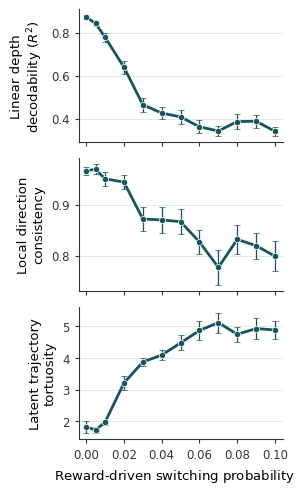

In [6]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(3.0, 5.0),
    sharex=True
)

plot_metric_panel(
    axes[0],
    agent_plot,
    x_col="p",
    y_col="linear_depth_r2",
    sem_col="linear_depth_r2_sem",
    color=COLORS["depth"],
    ylabel="Linear depth\ndecodability ($R^2$)",
)


plot_metric_panel(
    axes[1],
    agent_plot,
    x_col="p",
    y_col="transition_consistency",
    sem_col="transition_consistency_sem",
    color=COLORS["consistency"],
    ylabel="Local direction\nconsistency",
)

plot_metric_panel(
    axes[2],
    agent_plot,
    x_col="p",
    y_col="tortuosity",
    sem_col="tortuosity_sem",
    color=COLORS["tortuosity"],
    ylabel="Latent trajectory\ntortuosity",
    show_xlabel=True,
)

# Compact spacing
fig.subplots_adjust(
    left=0.30,
    right=0.98,
    top=0.98,
    bottom=0.12,
    hspace=0.12
)

save_agent_figure(fig, "agents_geometry_vs_p_early")

plt.show()
plt.close(fig)

## Mice

In [11]:
from scipy.stats import spearmanr

MOUSE_DIR = ROOT / "maze_metric_outputs_mice_last0.2"
MOUSE_FIG_DIR = ROOT / "paper_figures" / "figure_mice_entropy"
MOUSE_FIG_DIR.mkdir(parents=True, exist_ok=True)

mice = pd.read_csv(
    MOUSE_DIR / "summary.csv",
    dtype={"mouse_id": str, "seed": str}
)

if "mouse_id" not in mice.columns:
    mice["mouse_id"] = mice["seed"]

print(f"Loaded {len(mice)} mice")

Loaded 27 mice


In [12]:
MOUSE_METRICS = [
    ("linear_depth_r2", "Linear depth\ndecodability ($R^2$)"),
    ("transition_consistency", "Local direction\nconsistency"),
    ("tortuosity", "Latent trajectory\ntortuosity"),
]

ENTROPY_KEY = "node_entropy_normalized"
HIGHLIGHT_MICE = ["B4", "B5"]

MOUSE_COLORS = {
    "main": "#18545D",
    "highlight": "#A6533D",
    "ink": "#30363A",
    "grid": "#DFE7E5",
}

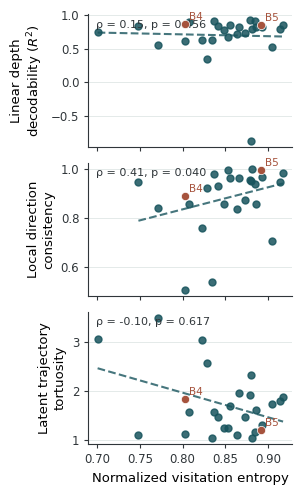

In [13]:

def plot_mouse_metric_panel(ax, df, metric, ylabel, show_xlabel=False):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(
        axis="y",
        color=MOUSE_COLORS["grid"],
        linewidth=0.6
    )
    ax.tick_params(
        direction="out",
        length=3,
        width=0.8,
        colors=MOUSE_COLORS["ink"]
    )

    data = df[
        ["mouse_id", ENTROPY_KEY, metric]
    ].dropna()

    x = data[ENTROPY_KEY].to_numpy()
    y = data[metric].to_numpy()

    other = ~data["mouse_id"].isin(HIGHLIGHT_MICE)

    ax.scatter(
        x[other],
        y[other],
        s=25,
        color=MOUSE_COLORS["main"],
        alpha=0.85,
        zorder=3
    )

    highlight = ~other

    ax.scatter(
        x[highlight],
        y[highlight],
        s=35,
        color=MOUSE_COLORS["highlight"],
        edgecolor="white",
        linewidth=0.5,
        zorder=4
    )

    if len(data) >= 3 and np.unique(x).size > 1:
        slope, intercept = np.polyfit(x, y, 1)

        x_line = np.linspace(x.min(), x.max(), 100)
        y_line = slope * x_line + intercept

        ax.plot(
            x_line,
            y_line,
            color=MOUSE_COLORS["main"],
            linewidth=1.5,
            linestyle="--",
            alpha=0.8,
            zorder=2
        )

    for _, row in data[
        data["mouse_id"].isin(HIGHLIGHT_MICE)
    ].iterrows():
        ax.annotate(
            row["mouse_id"],
            (row[ENTROPY_KEY], row[metric]),
            xytext=(3, 3),
            textcoords="offset points",
            fontsize=7.5,
            color=MOUSE_COLORS["highlight"]
        )

    if (
        len(data) >= 3
        and np.unique(x).size > 1
        and np.unique(y).size > 1
    ):
        rho, pval = spearmanr(x, y)

        ax.text(
            0.04, 0.96,
            f"ρ = {rho:.2f}, p = {pval:.3f}",
            transform=ax.transAxes,
            va="top",
            fontsize=8,
            color=MOUSE_COLORS["ink"]
        )

    ax.set_ylabel(ylabel)

    if show_xlabel:
        ax.set_xlabel("Normalized visitation entropy")


fig, axes = plt.subplots(
    3, 1,
    figsize=(3.0, 5.0),
    sharex=True
)

for i, (metric, ylabel) in enumerate(MOUSE_METRICS):
    plot_mouse_metric_panel(
        axes[i],
        mice,
        metric=metric,
        ylabel=ylabel,
        show_xlabel=(i == 2)
    )

entropy = mice[ENTROPY_KEY].dropna()
x_min = entropy.min()
x_max = entropy.max()

padding = max(0.01, (x_max - x_min) * 0.05)

axes[-1].set_xlim(
    max(0, x_min - padding),
    min(1, x_max + padding)
)

fig.subplots_adjust(
    left=0.30,
    right=0.98,
    top=0.98,
    bottom=0.12,
    hspace=0.12
)

for extension in ["svg", "pdf", "png"]:
    fig.savefig(
        MOUSE_FIG_DIR / f"mice_geometry_vs_entropy.{extension}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)
